In [3]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    ConfusionMatrixDisplay)

In [4]:
df=pd.read_csv("/Users/nidagallusandeep/Downloads/customer_churn_20000_rows.csv")

In [5]:
df.head()

,customer_id,tenure_months,monthly_charges,contract,internet_service,payment_method,tech_support,paperless_billing,senior_citizen,dependents,partner,total_charges,churn
0,CUST00001,7,92.07,Month-to-month,No,Mailed check,No,No,0,No,No,591.79,1
1,CUST00002,56,91.12,Month-to-month,Fiber optic,Electronic check,Yes,No,0,No,No,5672.22,0
2,CUST00003,48,40.27,Two year,Fiber optic,Credit card,No,Yes,1,No,Yes,2081.45,0
3,CUST00004,32,23.67,Month-to-month,DSL,Electronic check,No,Yes,0,No,Yes,870.61,0
4,CUST00005,32,50.38,Month-to-month,Fiber optic,Electronic check,No,No,0,No,Yes,1760.15,1


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   customer_id        20000 non-null  object 
 1   tenure_months      20000 non-null  int64  
 2   monthly_charges    19700 non-null  float64
 3   contract           20000 non-null  object 
 4   internet_service   20000 non-null  object 
 5   payment_method     19760 non-null  object 
 6   tech_support       19800 non-null  object 
 7   paperless_billing  20000 non-null  object 
 8   senior_citizen     20000 non-null  int64  
 9   dependents         20000 non-null  object 
 10  partner            20000 non-null  object 
 11  total_charges      20000 non-null  float64
 12  churn              20000 non-null  int64  
dtypes: float64(2), int64(3), object(8)
memory usage: 2.0+ MB


In [7]:
df.columns

Index(['customer_id', 'tenure_months', 'monthly_charges', 'contract',
       'internet_service', 'payment_method', 'tech_support',
       'paperless_billing', 'senior_citizen', 'dependents', 'partner',
       'total_charges', 'churn'],
      dtype='object')

In [8]:
df.describe()

,tenure_months,monthly_charges,senior_citizen,total_charges,churn
count,20000.000000,19700.000000,20000.000000,20000.000000,20000.000000
mean,36.250350,70.236895,0.158450,2540.999625,0.267100
std,20.749757,28.866664,0.365172,1901.485989,0.442456
min,1.000000,20.000000,0.000000,18.840000,0.000000
25%,18.000000,45.110000,0.000000,1030.807500,0.000000
50%,36.000000,70.395000,0.000000,2094.770000,0.000000
75%,54.000000,95.422500,0.000000,3713.087500,1.000000
max,72.000000,120.000000,1.000000,9613.740000,1.000000


In [9]:
df.isnull().sum()

customer_id            0
tenure_months          0
monthly_charges      300
contract               0
internet_service       0
payment_method       240
tech_support         200
paperless_billing      0
senior_citizen         0
dependents             0
partner                0
total_charges          0
churn                  0
dtype: int64

In [10]:
df["monthly_charges"]=df["monthly_charges"].fillna(df["monthly_charges"].mean())
df["payment_method"]=df["payment_method"].fillna(df["payment_method"].mode()[0])
df["tech_support"]=df["tech_support"].fillna(df["tech_support"].mode()[0])

In [11]:
df.isnull().sum()

customer_id          0
tenure_months        0
monthly_charges      0
contract             0
internet_service     0
payment_method       0
tech_support         0
paperless_billing    0
senior_citizen       0
dependents           0
partner              0
total_charges        0
churn                0
dtype: int64

In [12]:
df.duplicated().sum()

np.int64(0)

In [13]:
X = df.drop(columns=["customer_id", "churn"])
y = df["churn"]

In [14]:
numeric_features = [
    "tenure_months",
    "monthly_charges",
    "senior_citizen",
    "total_charges"]

categorical_features = [
    "contract",
    "internet_service",
    "payment_method",
    "tech_support",
    "paperless_billing",
    "dependents",
    "partner"]

In [15]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

In [16]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

In [17]:
from sklearn.linear_model import LogisticRegression
baseline_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(max_iter=2000))
])

baseline_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](11,)","['tenure_months','monthly_charges','contract',...,'dependents','partner', 'total_charges']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,11
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='p

In [18]:
y_pred = baseline_model.predict(X_test)

In [19]:
accuracy=accuracy_score(y_pred,y_test)
print("Accuracy:",accuracy)

Accuracy: 0.767


In [20]:
Precision=precision_score(y_pred,y_test)
print("Precision:",Precision)

Precision: 0.2978723404255319


In [21]:
Recall=recall_score(y_pred,y_test)
print("Recall:",Recall)

Recall: 0.5992217898832685


In [22]:
from sklearn.metrics import f1_score
f1 = f1_score(y_test, y_pred)
print("F1 Score:", f1)

F1 Score: 0.3979328165374677


In [23]:
from sklearn.metrics import classification_report
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.79      0.93      0.86      2966
           1       0.60      0.30      0.40      1034

    accuracy                           0.77      4000
   macro avg       0.70      0.61      0.63      4000
weighted avg       0.74      0.77      0.74      4000



# Confusion Matrix

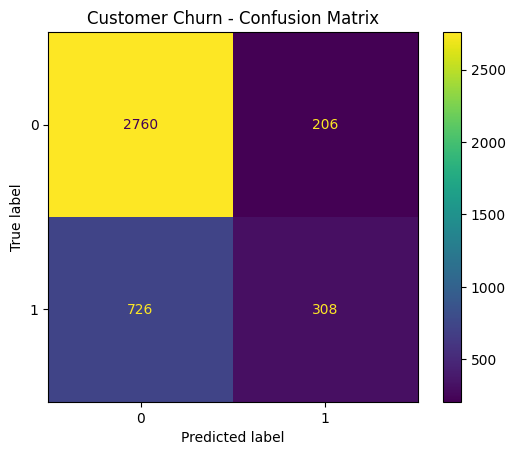

In [24]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt
ConfusionMatrixDisplay.from_predictions(y_test, y_pred)
plt.title("Customer Churn - Confusion Matrix")
plt.show()

In [25]:
# ROC-AUC Score
from sklearn.metrics import roc_auc_score
y_prob = baseline_model.predict_proba(X_test)[:, 1]
roc_auc = roc_auc_score(y_test, y_prob)
print("ROC-AUC Score:", roc_auc)

ROC-AUC Score: 0.7602219089070067
